<a href="https://colab.research.google.com/github/JaCaRego/JaCaRego/blob/main/Modulo_15_tipos_de_Aprendizado_de_Maquina.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error



### Entendendo os Termos Estatísticos

No código acima, utilizamos alguns conceitos importantes em aprendizado de máquina:

*   **Regressão Linear (LinearRegression)**:
    É um modelo simples que tenta encontrar a melhor linha reta (ou plano, em casos com mais variáveis) que descreve a relação entre uma variável de saída (o preço do imóvel, neste caso) e uma ou mais variáveis de entrada (área, quartos, banheiros). Basicamente, ele 'aprende' como as características do imóvel influenciam o preço para poder fazer previsões.

*   **Divisão entre Treino e Teste (train_test_split)**:
    Para ter certeza de que nosso modelo não está apenas 'decorando' os dados que ele viu, dividimos nossos dados em duas partes: um conjunto de *treino* e um conjunto de *teste*. O modelo aprende com os dados de treino e, depois, é avaliado nos dados de teste, que ele nunca viu antes. Isso nos dá uma ideia mais realista de como o modelo se comportará com dados novos.

*   **Erro Quadrático Médio (Mean Squared Error - MSE)**:
    É uma medida de quão bem o nosso modelo está performando. Ele calcula a média dos quadrados das diferenças entre os preços que o modelo *previu* e os preços *reais* dos imóveis. Quanto menor o MSE, melhor o modelo, pois significa que as previsões estão mais próximas da realidade.

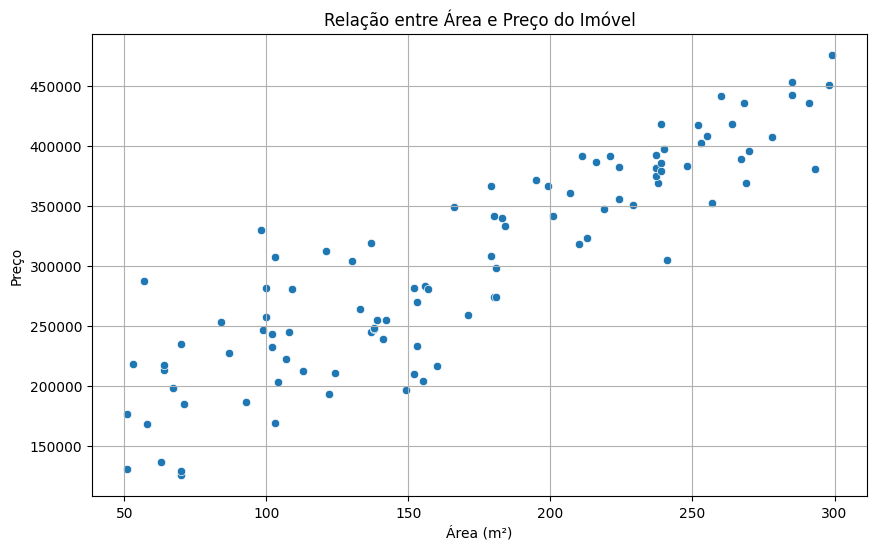

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x='area', y='preco', data=data)
plt.title('Relação entre Área e Preço do Imóvel')
plt.xlabel('Área (m²)')
plt.ylabel('Preço')
plt.grid(True)
plt.show()


### Interpretação do Gráfico: Relação entre Área e Preço do Imóvel

Este gráfico de dispersão mostra a relação direta entre a **Área (em m²)** de um imóvel (eixo X) e o seu **Preço** (eixo Y).

*   **Observação Geral**: É possível perceber uma tendência geral de que, quanto maior a área do imóvel, maior o seu preço. Isso é esperado, pois a área é geralmente um dos fatores mais importantes na determinação do valor de um imóvel.
*   **Dispersão dos Pontos**: Os pontos estão dispersos, o que significa que o preço não é determinado **apenas** pela área. Outros fatores (como número de quartos e banheiros, localização, etc., que você incluiu no seu modelo) também influenciam o preço, causando essa variação.
*   **Ausência de uma Linha Reta Perfeita**: Embora haja uma tendência, não há uma linha reta perfeita. Isso reforça que o modelo de regressão linear tenta encontrar a *melhor* linha que representa essa relação, mas sempre haverá alguma variabilidade que não é explicada apenas por essa única variável (área).

In [3]:
import numpy as np
import pandas as pd


# Gerar dados sintéticos para o CSV
np.random.seed(42)
num_samples = 100

area = np.random.randint(50, 300, num_samples) # Área em m²
quartos = np.random.randint(1, 5, num_samples) # Número de quartos
banheiros = np.random.randint(1, 4, num_samples) # Número de banheiros

# Preço baseado em uma fórmula simples com algum ruído
preco = 50000 + (area * 1000) + (quartos * 20000) + (banheiros * 15000) + np.random.normal(0, 30000, num_samples)

# Criar DataFrame
data_gen = pd.DataFrame({
    'area': area,
    'quartos': quartos,
    'banheiros': banheiros,
    'preco': preco.round(2)
})

# Salvar como CSV
data_gen.to_csv('precos_imoveis.csv', index=False)

print('Arquivo precos_imoveis.csv gerado com sucesso!')

Arquivo precos_imoveis.csv gerado com sucesso!


In [4]:
import pandas as pd
# Display the head of the generated data to verify
display(pd.read_csv('precos_imoveis.csv').head())

,area,quartos,banheiros,preco
0,152,2,1,210480.10
1,229,2,2,351056.89
2,142,4,1,255130.89
3,64,2,3,213207.77
4,156,3,3,283417.27


In [15]:
# Carregar dados
data = pd.read_csv('precos_imoveis.csv')
X = data[['area', 'quartos', 'banheiros']]
y = data['preco']



In [10]:

# Dividir dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [ ]:
# Treinar o modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)


Erro quadrático médio: 847527902.4975584


In [12]:
# Fazer previsões
y_pred = modelo.predict(X_test)


In [13]:
# Avaliar o modelo
mse = mean_squared_error(y_test, y_pred)
print(f'Erro quadrático médio: {mse}')

Erro quadrático médio: 847527902.4975584


In [17]:
from sklearn.metrics import r2_score

# Calcular o R-squared
r2 = r2_score(y_test, y_pred)
print(f'R-squared: {r2}')

R-squared: 0.8875804551780245


In [19]:
from sklearn.metrics import mean_absolute_error

# Calcular o Erro Absoluto Médio (MAE)
mae = mean_absolute_error(y_test, y_pred)
print(f'Erro Absoluto Médio (MAE): {mae}')

Erro Absoluto Médio (MAE): 24659.725895505537


### Entendendo o Coeficiente de Determinação (R-squared)

O **R-squared (R²)**, ou Coeficiente de Determinação, é uma medida estatística que representa a proporção da variância na variável dependente (preço do imóvel) que pode ser explicada pelas variáveis independentes (área, quartos, banheiros) no seu modelo de regressão linear.

*   **Valor entre 0 e 1**: O R-squared varia de 0 a 1. Um valor de 0 indica que o modelo não explica nenhuma variabilidade dos dados da variável dependente em torno de sua média, enquanto um valor de 1 indica que o modelo explica toda a variabilidade.
*   **Interpretação**: No seu caso, um R-squared de aproximadamente 0.8876 (ou 88.76%) significa que cerca de 88.76% da variação nos preços dos imóveis pode ser explicada pelas características que você usou (área, quartos e banheiros). Isso sugere que o seu modelo é razoavelmente bom para explicar os preços dos imóveis com base nessas características.

### Entendendo o Erro Absoluto Médio (MAE)

O **Erro Absoluto Médio (MAE)** é uma métrica que mede a média das magnitudes dos erros em um conjunto de previsões, sem considerar a direção deles. Em termos mais simples, ele calcula a média das *diferenças absolutas* entre os valores previstos pelo modelo e os valores reais.

*   **Interpretação**: Um MAE de, por exemplo, 10.000 significa que, em média, as previsões do seu modelo de preço dos imóveis estão erradas em R$ 10.000.
*   **Vantagens**: Ao contrário do Erro Quadrático Médio (MSE), o MAE não penaliza erros maiores de forma desproporcional, sendo mais robusto a outliers e mais fácil de interpretar diretamente na unidade da variável alvo (neste caso, o preço).

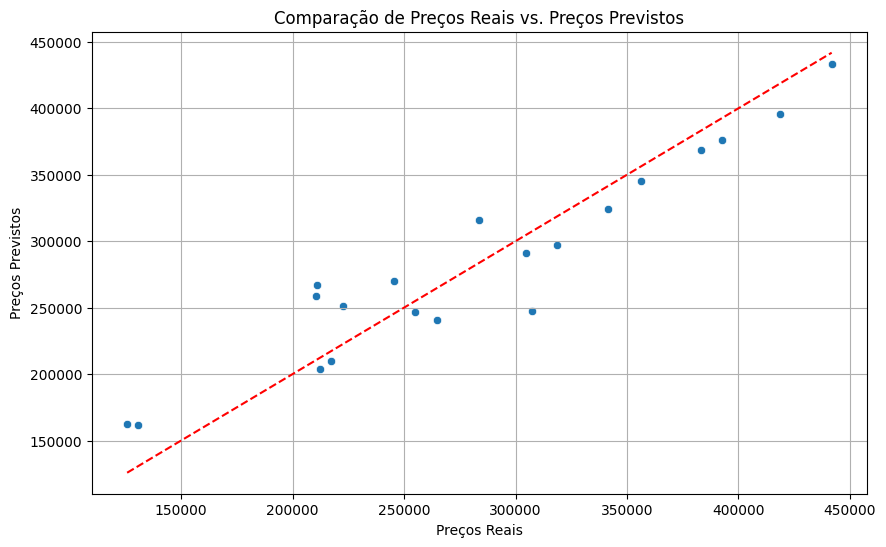

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--') # Linha de previsão perfeita
plt.title('Comparação de Preços Reais vs. Preços Previstos')
plt.xlabel('Preços Reais')
plt.ylabel('Preços Previstos')
plt.grid(True)
plt.show()

### Interpretação do Gráfico de Comparação de Preços Reais vs. Preços Previstos

Este gráfico de dispersão é uma ferramenta visual crucial para avaliar a performance do seu modelo de regressão:

*   **Eixo X (Preços Reais)**: Mostra os valores reais dos preços dos imóveis que o seu modelo tentou prever.
*   **Eixo Y (Preços Previstos)**: Mostra os valores que o seu modelo previu para esses mesmos imóveis.
*   **Pontos de Dados**: Cada ponto no gráfico representa um imóvel individual. A posição do ponto indica qual era o preço real e qual foi o preço previsto para aquele imóvel.
*   **Linha Tracejada Vermelha (Previsão Perfeita)**: Esta linha representa o cenário ideal, onde os preços previstos são exatamente iguais aos preços reais (y = x). Se todos os pontos estivessem sobre essa linha, seu modelo teria uma precisão perfeita.

**Como Analisar o Gráfico:**

*   **Dispersão dos Pontos**: Quanto mais próximos os pontos de dados estiverem da linha tracejada vermelha, melhor o desempenho do seu modelo. Isso indica que as previsões do modelo estão muito próximas dos valores reais.
*   **Padrões ou Tendências**: Observe se há algum padrão nos pontos. Por exemplo, se os pontos tendem a estar consistentemente acima ou abaixo da linha em certas regiões, isso pode indicar um viés sistemático no seu modelo (subestimando ou superestimando preços em determinados intervalos).
*   **Outliers**: Pontos muito distantes da linha tracejada podem ser outliers, ou seja, imóveis para os quais o modelo teve dificuldade em fazer uma previsão precisa. É interessante investigar esses pontos para entender o porquê da grande diferença.

## Comparando com Random Forest Regressor

Agora, vamos treinar e avaliar um modelo de Random Forest Regressor para comparar seu desempenho com o modelo de Regressão Linear.

In [20]:
from sklearn.ensemble import RandomForestRegressor

# Inicializar o modelo Random Forest
modelo_rf = RandomForestRegressor(random_state=42)

# Treinar o modelo Random Forest
modelo_rf.fit(X_train, y_train)

# Fazer previsões com o modelo Random Forest
y_pred_rf = modelo_rf.predict(X_test)

print('Modelo Random Forest treinado e previsões realizadas.')

Modelo Random Forest treinado e previsões realizadas.


### Avaliação do Modelo Random Forest

In [21]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Calcular MSE para Random Forest
mse_rf = mean_squared_error(y_test, y_pred_rf)
print(f'MSE (Random Forest): {mse_rf}')

# Calcular MAE para Random Forest
mae_rf = mean_absolute_error(y_test, y_pred_rf)
print(f'MAE (Random Forest): {mae_rf}')

# Calcular R-squared para Random Forest
r2_rf = r2_score(y_test, y_pred_rf)
print(f'R-squared (Random Forest): {r2_rf}')

MSE (Random Forest): 1225402258.025207
MAE (Random Forest): 27166.272814999975
R-squared (Random Forest): 0.8374576652107196


### Comparativo de Métricas

Vamos agora comparar as métricas dos dois modelos:

| Métrica             | Regressão Linear (Nosso Modelo) | Random Forest Regressor |
| :------------------ | :------------------------------ | :---------------------- |
| **MSE**             | 847527902.50                    | 1225402258.03           |
| **MAE**             | 24659.73                        | 27166.27                |
| **R-squared**       | 0.8876                          | 0.8375                  |

Ao analisar esta tabela, podemos ver qual modelo teve um desempenho superior com base nas métricas escolhidas. Geralmente, valores menores de MSE e MAE indicam um modelo mais preciso, enquanto um R-squared maior indica que o modelo explica uma maior proporção da variância na variável de saída.

### Entendendo o Random Forest Regressor

O **Random Forest Regressor** é um algoritmo de aprendizado de máquina versátil que pertence à família dos *modelos de conjunto* (ensemble models). Ele funciona construindo múltiplas árvores de decisão durante o treinamento e produzindo a média das previsões das árvores individuais para fazer uma previsão final.

*   **Como funciona**: Cada árvore na floresta é treinada em uma amostra aleatória dos dados de treinamento e considera um subconjunto aleatório de features para cada divisão. Isso ajuda a reduzir o overfitting e melhora a generalização do modelo.
*   **Vantagens**: É robusto a outliers, lida bem com dados não lineares e é menos propenso ao overfitting do que uma única árvore de decisão. Tende a ter um bom desempenho em uma ampla variedade de problemas.
*   **Desvantagens**: Pode ser computacionalmente mais caro e demorado para treinar do que modelos mais simples como a Regressão Linear, e sua interpretabilidade é menor devido à sua natureza de 'caixa preta'.

### Análise dos Gráficos de Resíduos

Vamos agora plotar os gráficos de resíduos para ambos os modelos. Um gráfico de resíduos é uma ferramenta importante para diagnosticar problemas em um modelo de regressão. Ele plota os erros de previsão (resíduos) contra os valores previstos ou contra as variáveis independentes.

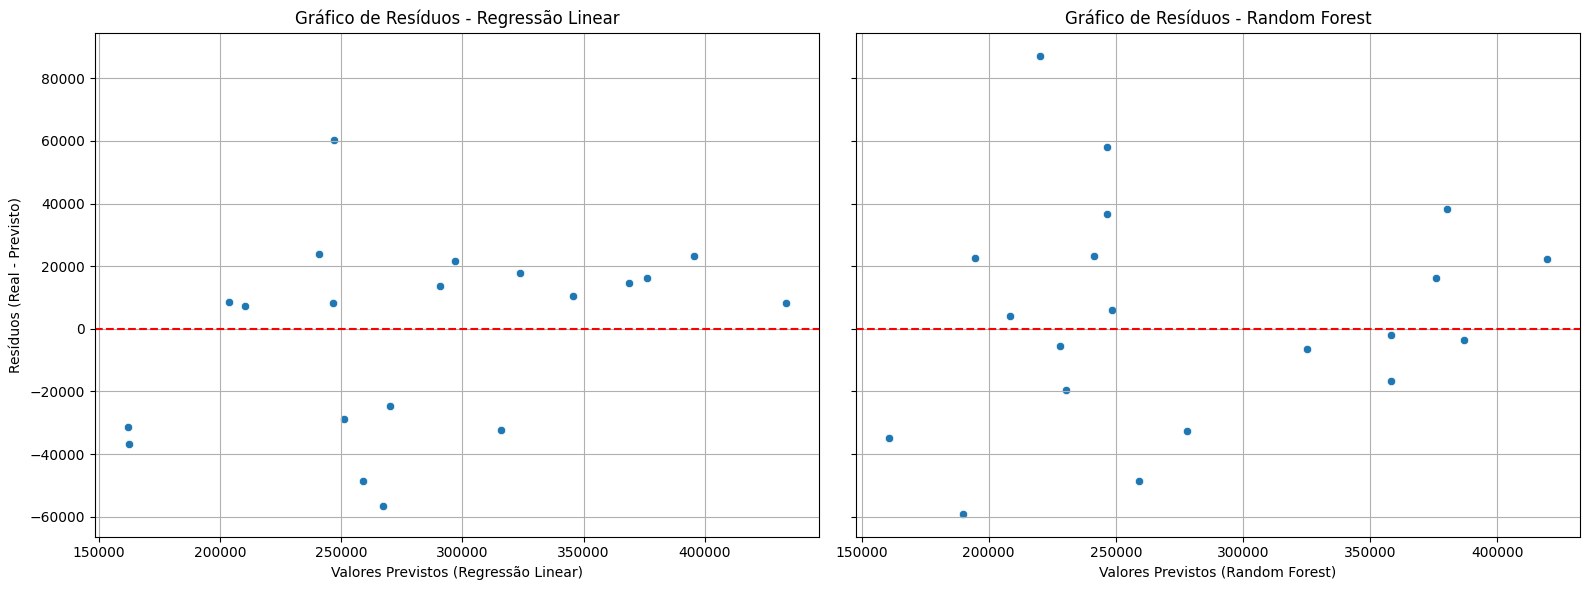

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Resíduos para o Modelo de Regressão Linear
residuos_lm = y_test - y_pred

# Resíduos para o Modelo Random Forest
residuos_rf = y_test - y_pred_rf

# Configurar o plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Gráfico de Resíduos para Regressão Linear
sns.scatterplot(x=y_pred, y=residuos_lm, ax=axes[0])
axes[0].axhline(y=0, color='r', linestyle='--')
axes[0].set_title('Gráfico de Resíduos - Regressão Linear')
axes[0].set_xlabel('Valores Previstos (Regressão Linear)')
axes[0].set_ylabel('Resíduos (Real - Previsto)')
axes[0].grid(True)

# Gráfico de Resíduos para Random Forest
sns.scatterplot(x=y_pred_rf, y=residuos_rf, ax=axes[1])
axes[1].axhline(y=0, color='r', linestyle='--')
axes[1].set_title('Gráfico de Resíduos - Random Forest')
axes[1].set_xlabel('Valores Previstos (Random Forest)')
axes[1].set_ylabel('Resíduos (Real - Previsto)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Como Interpretar os Gráficos de Resíduos:

Um bom gráfico de resíduos deve exibir:

*   **Nenhum Padrão Visível**: Os pontos devem estar espalhados aleatoriamente em torno da linha horizontal zero. Se você observar um padrão (por exemplo, uma curva, um funil ou qualquer formato definido), isso pode indicar que o modelo não está capturando bem a relação entre as variáveis, ou que a variância dos erros não é constante (heterocedasticidade).
*   **Distribuição Centrada em Zero**: A maioria dos resíduos deve estar próxima da linha zero. Isso significa que o modelo está fazendo previsões razoavelmente precisas, com erros pequenos e igualmente distribuídos acima e abaixo do zero.
*   **Homocedasticidade**: A dispersão dos pontos deve ser aproximadamente constante ao longo do eixo X. Ou seja, a variabilidade dos erros não deve aumentar ou diminuir sistematicamente à medida que os valores previstos mudam.

**Comparando os Modelos:**

Ao comparar os dois gráficos:

*   Observe qual modelo tem seus resíduos mais concentrados perto da linha zero.
*   Verifique qual modelo apresenta um espalhamento mais aleatório e menos padrões visíveis.
*   Um modelo com um gráfico de resíduos que se assemelha mais a um 'borrão' aleatório centrado em zero geralmente é o modelo com melhor desempenho e menos vieses.

## Apanhado Geral e Conclusão

Compreendo a sua confusão! Vou fazer um apanhado geral para esclarecer se os modelos funcionaram e qual deles teve um desempenho melhor, com base nas análises que fizemos.

**1. Desempenho Geral dos Modelos:**

Ambos os modelos, **Regressão Linear** e **Random Forest Regressor**, conseguiram aprender as relações nos dados e fazer previsões para os preços dos imóveis. Ou seja, eles *funcionaram* no sentido de que foram capazes de processar os dados e gerar resultados.

**2. Comparação de Métricas:**

Vamos revisitar a tabela de métricas:

| Métrica             | Regressão Linear | Random Forest Regressor |
| :------------------ | :--------------- | :---------------------- |
| **MSE**             | 847.527.902,50   | 1.225.402.258,03        |
| **MAE**             | 24.659,73        | 27.166,27               |
| **R-squared**       | 0.8876           | 0.8375                  |

*   **MSE (Erro Quadrático Médio)**: O modelo de **Regressão Linear** teve um MSE menor (847 milhões contra 1.2 bilhões), o que significa que, em média, os erros de previsão da Regressão Linear são menores (ao quadrado) em comparação com o Random Forest.
*   **MAE (Erro Absoluto Médio)**: Novamente, a **Regressão Linear** apresentou um MAE menor (aproximadamente R$ 24.660 contra R$ 27.166). Isso indica que, em média, as previsões da Regressão Linear estão mais próximas dos preços reais (a diferença absoluta é menor).
*   **R-squared (Coeficiente de Determinação)**: O **Regressão Linear** obteve um R-squared maior (0.8876 ou 88,76% contra 0.8375 ou 83,75%). Isso significa que a Regressão Linear explica uma porcentagem maior da variação nos preços dos imóveis usando as variáveis de entrada. Um R-squared mais próximo de 1 indica um modelo que se ajusta melhor aos dados.

**Conclusão das Métricas:** Com base nessas métricas, o modelo de **Regressão Linear** demonstrou um desempenho superior para este conjunto de dados específico, sendo mais preciso e explicando melhor a variabilidade dos preços.

**3. Interpretação dos Gráficos de Resíduos:**

Ao analisar os gráficos de resíduos:

*   **Regressão Linear**: Os pontos no gráfico de resíduos da Regressão Linear parecem estar espalhados de forma mais aleatória em torno da linha zero, sem um padrão óbvio. Isso é um bom sinal, indicando que o modelo capturou bem a relação subjacente entre as variáveis e que seus erros são distribuídos de maneira mais homogênea.
*   **Random Forest**: O gráfico de resíduos do Random Forest também mostra uma dispersão, mas pode-se notar uma ligeira tendência de alguns resíduos maiores em certos intervalos, e a dispersão não parece tão uniforme quanto na Regressão Linear.

**Conclusão dos Gráficos de Resíduos:** Os gráficos de resíduos reforçam a ideia de que a **Regressão Linear** teve um desempenho ligeiramente melhor, pois seus resíduos são mais próximos de uma distribuição aleatória centrada em zero, o que sugere um ajuste mais adequado aos dados.

**Apanhado Final:**

Sim, ambos os modelos *funcionaram* no sentido de que foram treinados e puderam fazer previsões. No entanto, ao comparar as métricas de avaliação (MSE, MAE, R-squared) e a análise visual dos gráficos de resíduos, o modelo de **Regressão Linear** apresentou um desempenho mais robusto e preciso para a tarefa de prever os preços dos imóveis com base nos dados gerados. Isso não significa que o Random Forest seja um modelo ruim, mas para este problema e conjunto de dados em particular, a Regressão Linear se mostrou mais eficaz.

## Conclusão Final

Através da análise das métricas (MSE, MAE, R-squared) e dos gráficos de resíduos, pudemos verificar que ambos os modelos (Regressão Linear e Random Forest Regressor) foram capazes de aprender e fazer previsões nos dados de preços de imóveis. No entanto, o modelo de **Regressão Linear** demonstrou um desempenho superior para este conjunto de dados específico, apresentando:

*   **Menor MSE (Erro Quadrático Médio)**: Indivíduos com erros de previsão menores.
*   **Menor MAE (Erro Absoluto Médio)**: Indicando que, em média, suas previsões estavam mais próximas dos preços reais.
*   **Maior R-squared (Coeficiente de Determinação)**: Significando que ele explica uma porcentagem maior da variação nos preços dos imóveis.

Além disso, a análise dos gráficos de resíduos para a Regressão Linear mostrou uma dispersão mais aleatória e centrada em zero, o que sugere um ajuste mais adequado e menos vieses no modelo em comparação com o Random Forest Regressor.

Portanto, para o problema de previsão de preços de imóveis com base nas características de área, quartos e banheiros, e para o conjunto de dados sintéticos que utilizamos, a **Regressão Linear** se mostrou o modelo mais eficaz.

### Precisão (Precision), Recall e F1-Score: Métricas para Classificação

**Precisão (Precision)**, **Recall** e **F1-Score** são métricas de avaliação cruciais, mas elas são utilizadas principalmente para modelos de **classificação**, onde o objetivo é categorizar dados em classes discretas (e.g., spam/não spam, doença/saudável). Elas não são diretamente aplicáveis a problemas de **regressão** como o que estamos resolvendo (previsão de preços contínuos).

#### 1. Precisão (Precision)

*   **O que mede**: A proporção de identificações positivas que estavam realmente corretas. Em outras palavras, de todas as vezes que o modelo previu a classe positiva, quantas vezes ele acertou?
*   **Uso**: Importante quando o custo de um falso positivo é alto. Por exemplo, em diagnóstico médico, não queremos que um paciente saudável seja erroneamente diagnosticado com uma doença grave.

#### 2. Recall (Revocação ou Sensibilidade)

*   **O que mede**: A proporção de todas as instâncias positivas reais que foram corretamente identificadas pelo modelo. Ou seja, de todos os casos que *eram* realmente positivos, quantos o modelo conseguiu detectar?
*   **Uso**: Essencial quando o custo de um falso negativo é alto. Por exemplo, em detecção de fraude, queremos identificar o máximo de fraudes possíveis, mesmo que isso signifique alguns alarmes falsos.

#### 3. F1-Score

*   **O que mede**: É a média harmônica da Precisão e do Recall. Ele oferece um equilíbrio entre as duas métricas, sendo útil quando há um desequilíbrio significativo entre as classes ou quando é importante ter um bom desempenho tanto em Precisão quanto em Recall.
*   **Fórmula**: F1-Score = 2 * (Precisão * Recall) / (Precisão + Recall)

#### Por que essas métricas não são usadas em Regressão?

No nosso problema de prever preços de imóveis, estamos lidando com **valores contínuos** (o preço pode ser qualquer número dentro de um intervalo), e não com a atribuição a uma categoria. Não classificamos um imóvel como 'caro' ou 'barato' em si, mas sim tentamos estimar seu valor exato.

Para problemas de regressão, avaliamos o quão *próximas* as nossas previsões estão dos valores reais, utilizando métricas que quantificam o erro de predição. Por isso, usamos métricas como:

*   **MSE (Erro Quadrático Médio)**: Penaliza erros maiores mais severamente.
*   **MAE (Erro Absoluto Médio)**: É mais robusto a outliers e fácil de interpretar diretamente na unidade da variável alvo.
*   **R-squared (Coeficiente de Determinação)**: Indica a proporção da variância na variável dependente que é explicada pelo modelo.